### Buckley-Leverett PINN noisy data informed example.
The Buckley Leverett constrained to Oleinik entropy condition, for inmisible, isotermal, horizonal two phase flow, with the conservation equation for the weatting phase saturation $S_{w}$ is defined as:
$$\phi \frac{\partial S_{w}}{\partial t}+v\frac{\partial f(S_{w})}{\partial x}=0, \qquad (x,t)\times[0,1],$$

constrained to the conditions: 

$$S(0, t)=1 - S_{nr},$$

as the boundary condition and 

$$S(x, 0)=S_{wr},$$

as the initial condition.

Having obtained the semi analytical solution, noise is added, from an univariated random function $g$ in the range $[0.0,1.0)$
 $$\hat{S}_{w} + g,$$

For this approximation the loss funtion model is constrained to the physical and data informed terms, such as:
$$\mathcal{L} = \mathcal{L}_{data} + \mathcal{L}_{\mathcal{B}} + \mathcal{L}_{physics}+ \mathcal{L}_{I}.$$

In [29]:
# Libraries
import numpy as np
import matplotlib.pyplot as plt

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import LinearLocator
from matplotlib import cm

import time
# Buckley-Leverett library
import BL as bl

import tensorflow as tf
from tensorflow.python.client import device_lib

In [30]:
device_list = device_lib.list_local_devices()

for devices in device_list:
    if devices.device_type == "GPU":
        print("="*100)
        print(devices.physical_device_desc)
        print("The GPU is being used")
        print("="*100)

device: 0, name: NVIDIA GeForce RTX 3080, pci bus id: 0000:01:00.0, compute capability: 8.6
The GPU is being used


In [31]:
# Physics parameters
krwmax = 0.3      # Maximum relative permeability for water
nw = 2            # Saturation exponent for water
krnwmax = 0.8     # Maximum relative permeability for non-water (oil)
nnw = 2           # Saturation exponent for non-water (oil)
swc = 0.2         # Connate (irreducible) water saturation
snwr = 0.2        # Residual saturation of the non-water phase
muw = 1.0e-3      # Viscosity of water (Pa.s)
munw = 5.0e-3     # Viscosity of non-water phase (Pa.s)
qt = 0.1          # Flow rate (arbitrary units)
A = 1.0           # Cross-sectional area
phi = 0.2         # Porosity
l = 1.0           # Length of domain
t = 1.0
times = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0] # Times for simulation (arbitrary units)

Nx = 100
Nt = 100

dt = t / Nt
dx = l / Nx

In [32]:
# Initialize Brooks-Corey model
bc_model = bl.BrooksCorey(swc=swc, snwr=snwr, nw=nw, nnw=nnw,
                       krwmax=krwmax, krnwmax=krnwmax,
                       muw=muw, munw=munw)
# Semi analytic solution
semi = bl.analytic_solution(Swc=swc, Sor=snwr, krw0=krwmax, kro0=krnwmax, nw=nw, no=nnw,
                         mu_w=muw, mu_o=munw, Nx=Nx, Nt=Nt, A=A, qt=qt, phi=phi,
                         fw_tangent = bc_model.fw_tangent, sw_tangent = bc_model.sw_tangent,
                         L=l, T=l)

u = semi.create_solution()


Shock properties (Welge tangent):
  fw(swc): 0.0000
  Shock saturation (sw_tangent): 0.5542
  fw at shock: 0.7956
  Shock slope (alpha): 2.2463



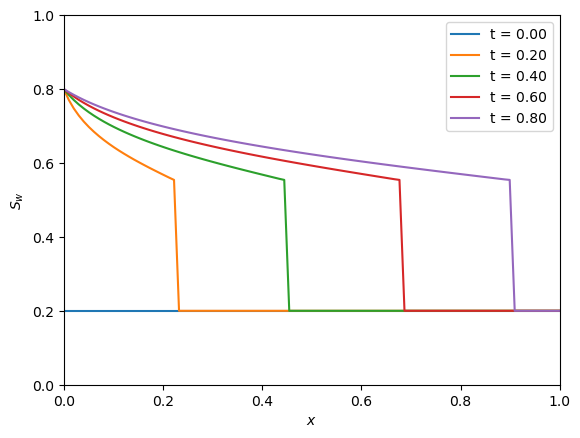

In [33]:
x = np.linspace(0, l, Nx)
plt.figure()
for i in range(Nt):
    if i % 20 == 0:
        plt.plot(x, u[i], label=f't = {i*dt:.2f}')
plt.xlabel("$x$")
plt.ylabel("$S_{w}$")
plt.ylim([0.0, 1.0])
plt.xlim([0,1])
plt.legend()
plt.show()

In [34]:
u = np.array(u)
u_noisy = u  + 0.1 * np.random.random(u.shape) - 0.05

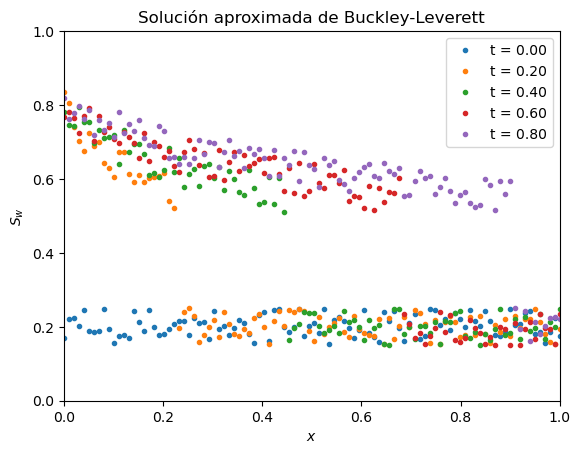

In [35]:
plt.figure()
for i in range(Nt):
    if i % 20 == 0:
        plt.plot(x, u_noisy[i],'.', label=f't = {i*dt:.2f}')
plt.xlabel("$x$")
plt.ylabel("$S_{w}$")
plt.title("Solución aproximada de Buckley-Leverett")
plt.ylim([0.0, 1.0])
plt.xlim([0,1])
plt.legend()
plt.show()

In [36]:
class PINN(tf.keras.Model):
    def __init__(self, neurons, layers, dim_in, dim_out):
        super(PINN, self).__init__() # Call methods from the mother class tf.keras.Model
        # Initial layer
        self.fci = tf.keras.layers.Dense(neurons, activation=None)
        # Output layer
        self.fco = tf.keras.layers.Dense(dim_out, activation=None)
        # Activation function
        self.tanh = tf.keras.layers.Activation('tanh')
        # Empty list for hidden layers
        self.mlps = []
        # Add hidden layers
        for _ in range(layers):
            self.mlps.append(tf.keras.layers.Dense(neurons, activation=None))
    
    def call(self, x, t):
        # Concatenate X and T
        x_i = tf.concat([x, t], axis=1)
        x_out = x_i # Create an output vector with the size of the input
        x_out = self.fci(x_out) # Evaluate x_i sequentaly using x_out
        
        for mlp_x in self.mlps:
            x_out = mlp_x(x_out)
            x_out = self.tanh(x_out)
        # Final x_out calculation
        x_out = self.fco(x_out)
        return x_out
        
# Physics loss function with entropy formulation and data
def physics_informed_loss_diff(model, bc_model, x, t, qt, phi, A, 
                               x_data=None, t_data=None, s_data=None, lambda_data=1.0):
    
    with tf.GradientTape(persistent=True) as tape:
        tape.watch(x)
        tape.watch(t)
        
        # Predict saturation
        sw_pred = model(x, t)
        
        # Fractional flow calculation with entropy fix
        fw = bc_model.fractional_flow(sw_pred)
        
        # Apply entropy fix: for S < sw_tangent, use linear fw = fw_swc + alpha * (S - swc)
        alpha = bc_model.alpha_tangent
        sw_tangent = bc_model.sw_tangent
        fw_swc = bc_model.fw_swc
        
        # Apply the entropy condition (shock capturing)
        fw = tf.where(sw_pred < sw_tangent, 
                      fw_swc + alpha * (sw_pred - swc),
                      fw)
    
    # Compute derivatives
    sw_t = tape.gradient(sw_pred, t)
    fw_x = tape.gradient(fw, x)
    
    del tape
    
    # Buckley-Leverett equation residual
    residual = sw_t + (qt / phi / A) * fw_x
    
    # Initial condition: S(x, 0) = swc
    t_zero = tf.zeros_like(t)
    sw_initial = model(x, t_zero)
    
    # Boundary condition: S(0, t) = 1-snwr
    x_zero = tf.zeros_like(x)
    sw_boundary = model(x_zero, t)
    
    # Residual forms of the loss funtions
    loss_physics = tf.reduce_mean(tf.abs(residual))
    loss_initial = tf.reduce_mean(tf.abs(sw_initial - swc))
    loss_boundary = tf.reduce_mean(tf.abs(sw_boundary - (1 - snwr)))
    
    # Data loss
    loss_data = tf.constant(0.0)
    if x_data is not None and t_data is not None and s_data is not None:
        s_pred_data = model(x_data, t_data)
        loss_data = tf.reduce_mean(tf.abs(s_pred_data - s_data))
    
    total_loss = loss_physics + loss_boundary + loss_initial + lambda_data * loss_data
    
    return total_loss, loss_physics, loss_boundary, loss_initial, loss_data

@tf.function
def train_step(model, bc_model, optimizer, X, T, qt, phi, A, 
               x_data, t_data, s_data, lambda_data):
    """Single training step"""
    with tf.GradientTape() as tape:
        loss, loss_physics, loss_boundary, loss_initial, loss_data = \
            physics_informed_loss_diff(model, bc_model, X, T, qt, phi, A,
                                     x_data, t_data, s_data, lambda_data)
    
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    
    return loss, loss_physics, loss_boundary, loss_initial, loss_data

In [37]:
# Generate data
Use_data = True
lambda_data = 10.0

In [38]:
# Load numerical solution
data_array = u_noisy.T.copy()

# Define coordinates
x_data_coords = np.linspace(0, l, data_array.shape[0])
t_data_coords = np.linspace(0, t, data_array.shape[1])

# Create meshgrid and flatten
X_data_mesh, T_data_mesh = np.meshgrid(x_data_coords, t_data_coords, indexing='ij')
x_data_flat = X_data_mesh.flatten()
t_data_flat = T_data_mesh.flatten()
s_data_flat = data_array.flatten()

if Use_data:
    x_data_tensor = tf.Variable(x_data_flat.reshape(-1, 1), dtype=tf.float32)
    t_data_tensor = tf.Variable(t_data_flat.reshape(-1, 1), dtype=tf.float32)
    s_data_tensor = tf.constant(s_data_flat.reshape(-1, 1), dtype=tf.float32)
    
    print(f"\nData loaded: {len(x_data_flat)} observation points")
    print(f"Data domain: x ∈ [{x_data_flat.min():.2f}, {x_data_flat.max():.2f}], "
          f"t ∈ [{t_data_flat.min():.2f}, {t_data_flat.max():.2f}]")
    print(f"Saturation range: S ∈ [{s_data_flat.min():.3f}, {s_data_flat.max():.3f}]")
    print(f"Data loss weight: {lambda_data}")
else:
    x_data_tensor = None
    t_data_tensor = None
    s_data_tensor = None
    print("No data for the PINN training")


Data loaded: 10000 observation points
Data domain: x ∈ [0.00, 1.00], t ∈ [0.00, 1.00]
Saturation range: S ∈ [0.150, 0.850]
Data loss weight: 10.0


In [39]:
# =============================================================================
# --------------------------  Collocation points   ----------------------------
# =============================================================================
# Create collocation points
print("Creating collocation points...")
x_col = np.linspace(0.001, l, 500).reshape(-1, 1)
t_col = np.linspace(0.00, max(times), 100).reshape(-1, 1)

X, T = np.meshgrid(x_col.flatten(), t_col.flatten(), indexing='ij')
X = tf.Variable(X.reshape(-1, 1), dtype=tf.float32)
T = tf.Variable(T.reshape(-1, 1), dtype=tf.float32)

X_np = X.numpy()
T_np = T.numpy()

x_c = np.linspace(0,1,50).reshape(-1, 1)
y_c = np.linspace(0,1,50).reshape(-1, 1)
x_c, y_c = np.meshgrid(x_c.flatten(), y_c.flatten(), indexing='ij')

x_c_b = np.zeros(50)
y_c_b = np.linspace(0,1,50)
print("Done!")

Creating collocation points...
Done!


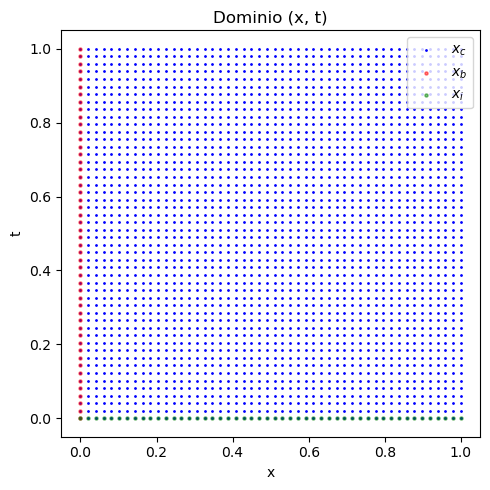

In [40]:
# Plot meshgrid
plt.figure(figsize=(5, 5))
plt.scatter(x_c, y_c , color='blue', s=1.0, alpha=1.0, label='$x_{c}$')
plt.scatter(x_c_b, y_c_b , color='red', s=5.0, alpha=0.5, label='$x_{b}$')
plt.scatter(y_c_b, x_c_b , color='green', s=5.0, alpha=0.5, label='$x_{i}$')
#if Use_data:
#    plt.scatter(x_data_flat[::2], t_data_flat[::2], color='red', s=0.2, alpha=0.5, label='$x_{d}$')
plt.xlabel("x")
plt.ylabel("t")
plt.title("Dominio (x, t)")
plt.legend()
plt.tight_layout()
plt.show()

In [41]:
print("Initializing PINN model...")
model = PINN(neurons=64, layers=5, dim_in=2, dim_out=1)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)

# Training logs
epochs_log = []
loss_totals = []
loss_physics_acc = []
loss_init_acc = []
loss_boundary_acc = []
loss_data_acc = []

num_epochs = 20000
print(f"\nStarting training for {num_epochs} epochs...\n")
starting_time = time.time()
print ("="*100)
for epoch in range(num_epochs):
    loss, loss_physics, loss_boundary, loss_initial, loss_data = train_step(
        model, bc_model, optimizer, X, T, qt, phi, A,
        x_data_tensor, t_data_tensor, s_data_tensor, lambda_data)
    
    if epoch % 500 == 0 or epoch + 1 == num_epochs:
        print(f"Epoch {epoch}/{num_epochs}, Loss: {loss.numpy():.5f}, "
              f"Physics: {loss_physics.numpy():.5f}, "
              f"Initial: {loss_initial.numpy():.5f}, "
              f"Boundary: {loss_boundary.numpy():.5f}, "
              f"Data: {loss_data.numpy():.5f}")
    
    epochs_log.append(epoch)
    loss_totals.append(loss.numpy())
    loss_physics_acc.append(loss_physics.numpy())
    loss_init_acc.append(loss_initial.numpy())
    loss_boundary_acc.append(loss_boundary.numpy())
    loss_data_acc.append(loss_data.numpy())
print ("="*100)
print("\nTraining complete!")
print("Training time %1.5f"%((time.time()-starting_time)/60.0))

Initializing PINN model...

Starting training for 20000 epochs...

Epoch 0/20000, Loss: 10.89863, Physics: 0.79182, Initial: 0.44105, Boundary: 0.99872, Data: 0.86670
Epoch 500/20000, Loss: 0.45887, Physics: 0.04311, Initial: 0.02054, Boundary: 0.03849, Data: 0.03567
Epoch 1000/20000, Loss: 0.35110, Physics: 0.02483, Initial: 0.00602, Boundary: 0.03165, Data: 0.02886
Epoch 1500/20000, Loss: 0.31336, Physics: 0.01847, Initial: 0.00446, Boundary: 0.01761, Data: 0.02728
Epoch 2000/20000, Loss: 0.31210, Physics: 0.01789, Initial: 0.00893, Boundary: 0.01383, Data: 0.02715
Epoch 2500/20000, Loss: 0.30300, Physics: 0.01546, Initial: 0.00891, Boundary: 0.01220, Data: 0.02664
Epoch 3000/20000, Loss: 0.29659, Physics: 0.01440, Initial: 0.00751, Boundary: 0.01135, Data: 0.02633
Epoch 3500/20000, Loss: 0.29391, Physics: 0.01404, Initial: 0.00713, Boundary: 0.01045, Data: 0.02623
Epoch 4000/20000, Loss: 0.28729, Physics: 0.01250, Initial: 0.00584, Boundary: 0.00946, Data: 0.02595
Epoch 4500/20000, 

In [42]:
x_test = np.linspace(0, l, Nx)
dt = 1 / Nt
u_pred = np.zeros([Nt, Nx])

for i in range(Nt):
    t_val = i * dt
    x_plot = tf.constant(x_test, dtype=tf.float32)
    x_plot = tf.reshape(x_plot, (-1, 1))
    t_plot = tf.fill(tf.shape(x_plot), t_val)
    u_pred[i] = model(x_plot, t_plot).numpy().reshape(100,)

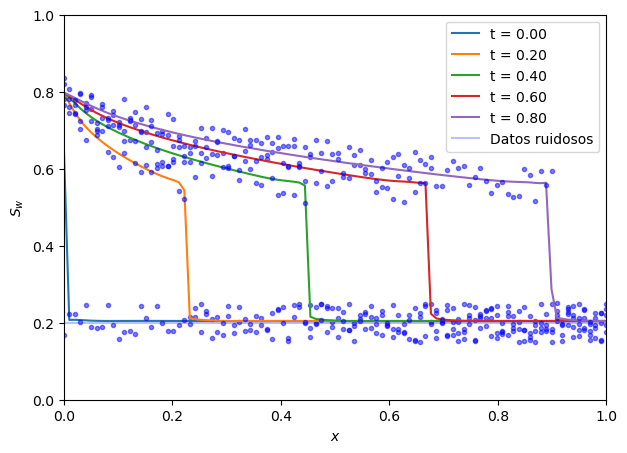

In [49]:
plt.figure(figsize=[7,5])

for i in range(100):
    if i%20 == 0:
        plt.plot(x_test, u_pred[i], label=f't = {i*dt:.2f}')
        plt.plot(x_test, u_noisy[i], "b.",alpha=0.5)

plt.plot(x_test, u[0], "b-",alpha=0.25, label="Datos ruidosos")
plt.xlabel("$x$")
plt.ylabel("$S_{w}$")
plt.ylim([0.0, 1.0])
plt.xlim([0,1])
plt.legend()
plt.show()

<Figure size 640x480 with 0 Axes>

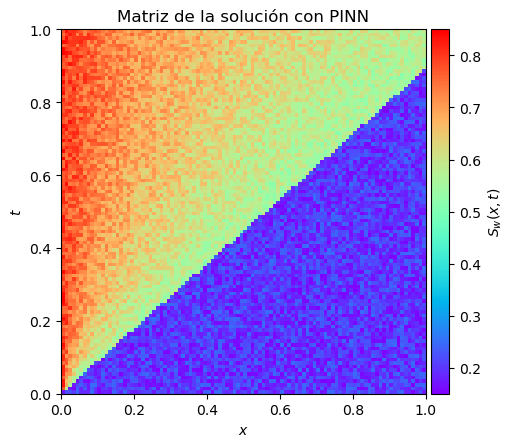

In [44]:
plt.figure()
fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(u_noisy, cmap='rainbow', extent=[0, 1, 0, 1], origin='lower')
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('$S_{w}(x, t)$')
ax.set_xlabel("$x$")
ax.set_ylabel("$t$")
ax.set_title("Matriz de la solución con PINN")
plt.show()

<Figure size 640x480 with 0 Axes>

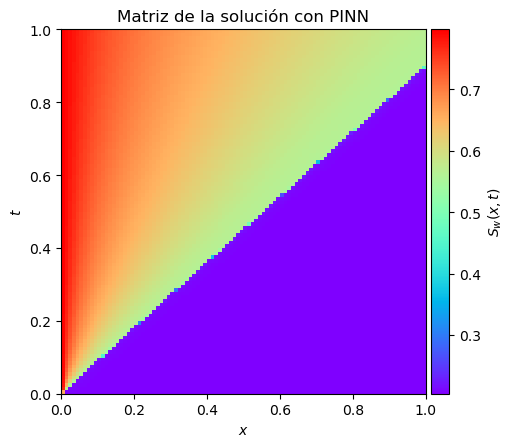

In [45]:
plt.figure()
fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(u_pred, cmap='rainbow', extent=[0, 1, 0, 1], origin='lower')
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('$S_{w}(x, t)$')
ax.set_xlabel("$x$")
ax.set_ylabel("$t$")
ax.set_title("Matriz de la solución con PINN")
plt.show()

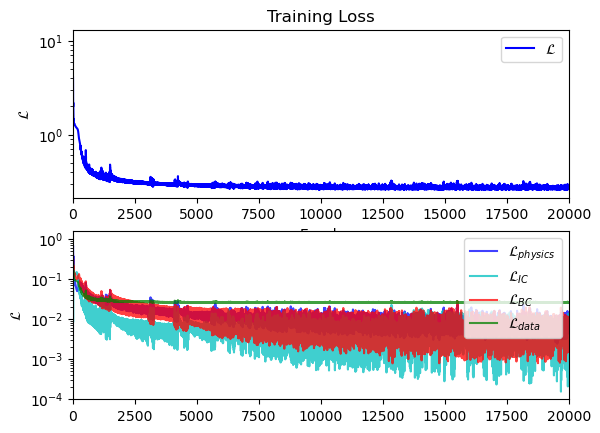

In [46]:
plt.figure()
plt.subplot(2,1,1)
plt.semilogy(epochs_log, loss_totals,"b-", label="$\mathcal{L}$")
plt.xlabel('Epoch')
plt.title('Training Loss')
plt.ylabel("$\mathcal{L}$")
plt.legend()
plt.xlim([0, num_epochs])
plt.yscale("log")
plt.subplot(2,1,2)
plt.semilogy(epochs_log, loss_physics_acc,"b",alpha=0.75, label="$\mathcal{L}_{physics}$")
plt.semilogy(epochs_log, loss_init_acc,"c",alpha=0.75, label='$\mathcal{L}_{IC}$')
plt.semilogy(epochs_log, loss_boundary_acc,"r",alpha=0.75, label='$\mathcal{L}_{BC}$')
plt.semilogy(epochs_log, loss_data_acc,"g",alpha=0.75, label='$\mathcal{L}_{data}$')
plt.ylabel("$\mathcal{L}$")
plt.legend()
plt.yscale("log")
plt.xlim([0, num_epochs])
plt.show()